<a href="https://colab.research.google.com/github/JasmineNasywa/PCVK_Ganjil_2026/blob/main/Week5_08.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [26]:
# ===== SEL IDENTITAS - JANGAN DIHAPUS, HARUS SEL PERTAMA =====
import sys, platform, hashlib, datetime, zoneinfo

NAMA = 'Jasmine Naswa N'
NIM  = '244107020119'    # ganti dengan NIM Anda

N    = int(NIM[-3:])
PARAM = {
    'bins' : 2 ** ((N % 4) + 3),
    'clip' : round(1.0 + (N % 5) * 0.5, 1),
    'tile' : (N % 4) + 2,
    'L'    : 2 ** ((N % 3) + 1),
}
waktu = datetime.datetime.now(zoneinfo.ZoneInfo('Asia/Jakarta'))

print('NAMA     :', NAMA)
print('NIM      :', NIM, '| N =', N)
for k, v in PARAM.items():
    print('%-6s : ' % k, v)
print('WAKTU    :', waktu.strftime('%Y-%m-%d %H:%M:%S %Z'))
print('SISTEM   :', sys.version.split()[0], platform.platform())
kunci = NIM + '|' + waktu.strftime('%Y-%m-%d')
print('TOKEN    :', hashlib.sha256(kunci.encode()).hexdigest()[:16])

NAMA     : Jasmine Naswa N
NIM      : 244107020119 | N = 119
bins   :  64
clip   :  3.0
tile   :  5
L      :  8
WAKTU    : 2026-09-27 16:39:13 WIB
SISTEM   : 3.13.15 Linux-6.6.122+-x86_64-with-glibc2.39
TOKEN    : 3983d5e8e5307132


In [1]:
import cv2 as cv
from google.colab.patches import cv2_imshow
import numpy as np
import matplotlib.pyplot as plt
from skimage import io
import math
import os
import glob

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


<BarContainer object of 256 artists>

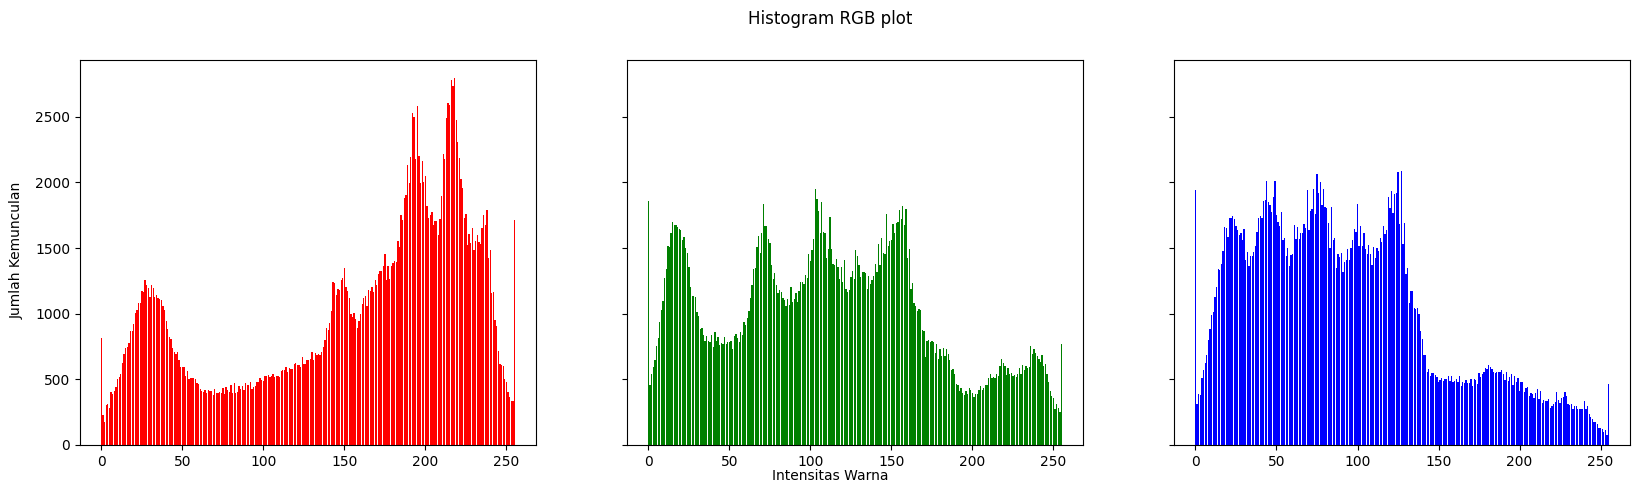

In [5]:
# membuat histogram image (manual)
img = cv.imread('/content/drive/MyDrive/PCVK/lena.jpg')
img = cv.cvtColor(img, cv.COLOR_BGR2RGB)

height, width, depth = np.shape(img)
names = np.arange(256)

red = [0]*256
green = [0]*256
blue = [0]*256
for y in range(0, height) :
    for x in range(0, width) :
      red[img[y][x][0]] += 1
      green[img[y][x][1]] += 1
      blue[img[y][x][2]] += 1

names = np.arange(256)
fig, axs = plt.subplots(1, 3, figsize=[20,5], sharex=True, sharey=True)
fig.suptitle('Histogram RGB plot')
fig.text(0.09, 0.5, 'Jumlah Kemunculan', va='center', rotation='vertical')
fig.text(0.5, 0.04, 'Intensitas Warna', ha='center')
axs[0].bar(names, red, color='red')
axs[1].bar(names, green, color='green')
axs[2].bar(names, blue, color='blue')

=== CEK SELISIH MAKSIMUM ANTAR METODE ===
Selisih Max Manual vs NumPy (Red)   : 0
Selisih Max Manual vs NumPy (Green) : 0
Selisih Max Manual vs NumPy (Blue)  : 0
----------------------------------------
Selisih Max Manual vs OpenCV (Red)  : 0.0
Selisih Max Manual vs OpenCV (Green): 0.0
Selisih Max Manual vs OpenCV (Blue) : 0.0


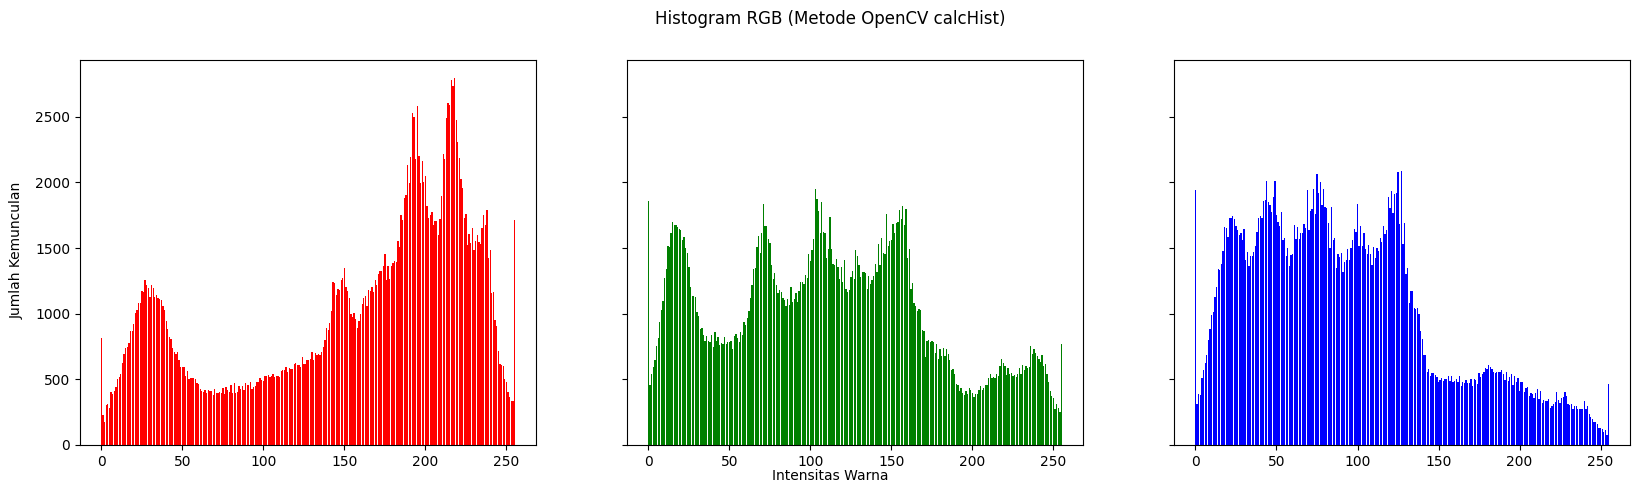

In [8]:

path = '/content/drive/MyDrive/PCVK/lena.jpg'
img = cv.imread(path)
img = cv.cvtColor(img, cv.COLOR_BGR2RGB)

height, width, depth = img.shape
names = np.arange(256)

#Manual
red_man = [0]*256
green_man = [0]*256
blue_man = [0]*256

for y in range(0, height):
    for x in range(0, width):
        red_man[img[y, x, 0]] += 1
        green_man[img[y, x, 1]] += 1
        blue_man[img[y, x, 2]] += 1

red_man = np.array(red_man)
green_man = np.array(green_man)
blue_man = np.array(blue_man)

#NAMPY.HISTOGRAM
# Menggunakan numpy.histogram untuk tiap channel (R, G, B)
red_np, _ = np.histogram(img[:, :, 0], bins=256, range=[0, 256])
green_np, _ = np.histogram(img[:, :, 1], bins=256, range=[0, 256])
blue_np, _ = np.histogram(img[:, :, 2], bins=256, range=[0, 256])

#CV.CALCHIST

red_cv = cv.calcHist([img], [0], None, [256], [0, 256]).flatten()
green_cv = cv.calcHist([img], [1], None, [256], [0, 256]).flatten()
blue_cv = cv.calcHist([img], [2], None, [256], [0, 256]).flatten()

#Hitung selisih
print("=== CEK SELISIH MAKSIMUM ANTAR METODE ===")
print("Selisih Max Manual vs NumPy (Red)   :", np.max(np.abs(red_man - red_np)))
print("Selisih Max Manual vs NumPy (Green) :", np.max(np.abs(green_man - green_np)))
print("Selisih Max Manual vs NumPy (Blue)  :", np.max(np.abs(blue_man - blue_np)))
print("-" * 40)
print("Selisih Max Manual vs OpenCV (Red)  :", np.max(np.abs(red_man - red_cv)))
print("Selisih Max Manual vs OpenCV (Green):", np.max(np.abs(green_man - green_cv)))
print("Selisih Max Manual vs OpenCV (Blue) :", np.max(np.abs(blue_man - blue_cv)))

#Visualisasi Plot
fig, axs = plt.subplots(1, 3, figsize=[20, 5], sharex=True, sharey=True)
fig.suptitle('Histogram RGB (Metode OpenCV calcHist)')
fig.text(0.09, 0.5, 'Jumlah Kemunculan', va='center', rotation='vertical')
fig.text(0.5, 0.04, 'Intensitas Warna', ha='center')
axs[0].bar(names, red_cv, color='red')
axs[1].bar(names, green_cv, color='green')
axs[2].bar(names, blue_cv, color='blue')
plt.show()

In [10]:

image_paths = [
    '/content/drive/MyDrive/PCVK/lena.jpg',
    '/content/drive/MyDrive/PCVK/KTP1B.jpeg'
]

for idx, path in enumerate(image_paths, start=1):
    print(f"MEMPROSES GAMBAR KE-{idx}: {path.split('/')[-1]}")


    img = cv.imread(path)
    if img is None:
        print(f"Error: Gambar di path {path} tidak ditemukan! Cek lagi lokasinya.")
        continue

    img = cv.cvtColor(img, cv.COLOR_BGR2RGB)
    height, width, depth = img.shape
    names = np.arange(256)

    #Manual
    red_man = [0]*256
    green_man = [0]*256
    blue_man = [0]*256

    for y in range(0, height):
        for x in range(0, width):
            red_man[img[y, x, 0]] += 1
            green_man[img[y, x, 1]] += 1
            blue_man[img[y, x, 2]] += 1

    red_man = np.array(red_man)
    green_man = np.array(green_man)
    blue_man = np.array(blue_man)

    #numpy.histogram
    red_np, _ = np.histogram(img[:, :, 0], bins=256, range=[0, 256])
    green_np, _ = np.histogram(img[:, :, 1], bins=256, range=[0, 256])
    blue_np, _ = np.histogram(img[:, :, 2], bins=256, range=[0, 256])

    #cv.calcHist
    red_cv = cv.calcHist([img], [0], None, [256], [0, 256]).flatten()
    green_cv = cv.calcHist([img], [1], None, [256], [0, 256]).flatten()
    blue_cv = cv.calcHist([img], [2], None, [256], [0, 256]).flatten()

    #Pembuktian Selisih Maksimum
    print("--- Cek Selisih Maksimum Manual vs NumPy ---")
    print("Red   :", np.max(np.abs(red_man - red_np)))
    print("Green :", np.max(np.abs(green_man - green_np)))
    print("Blue  :", np.max(np.abs(blue_man - blue_np)))

    print("--- Cek Selisih Maksimum Manual vs OpenCV ---")
    print("Red   :", np.max(np.abs(red_man - red_cv)))
    print("Green :", np.max(np.abs(green_man - green_cv)))
    print("Blue  :", np.max(np.abs(blue_man - blue_cv)))

MEMPROSES GAMBAR KE-1: lena.jpg
--- Cek Selisih Maksimum Manual vs NumPy ---
Red   : 0
Green : 0
Blue  : 0
--- Cek Selisih Maksimum Manual vs OpenCV ---
Red   : 0.0
Green : 0.0
Blue  : 0.0
MEMPROSES GAMBAR KE-2: KTP1B.jpeg
--- Cek Selisih Maksimum Manual vs NumPy ---
Red   : 0
Green : 0
Blue  : 0
--- Cek Selisih Maksimum Manual vs OpenCV ---
Red   : 0.0
Green : 0.0
Blue  : 0.0


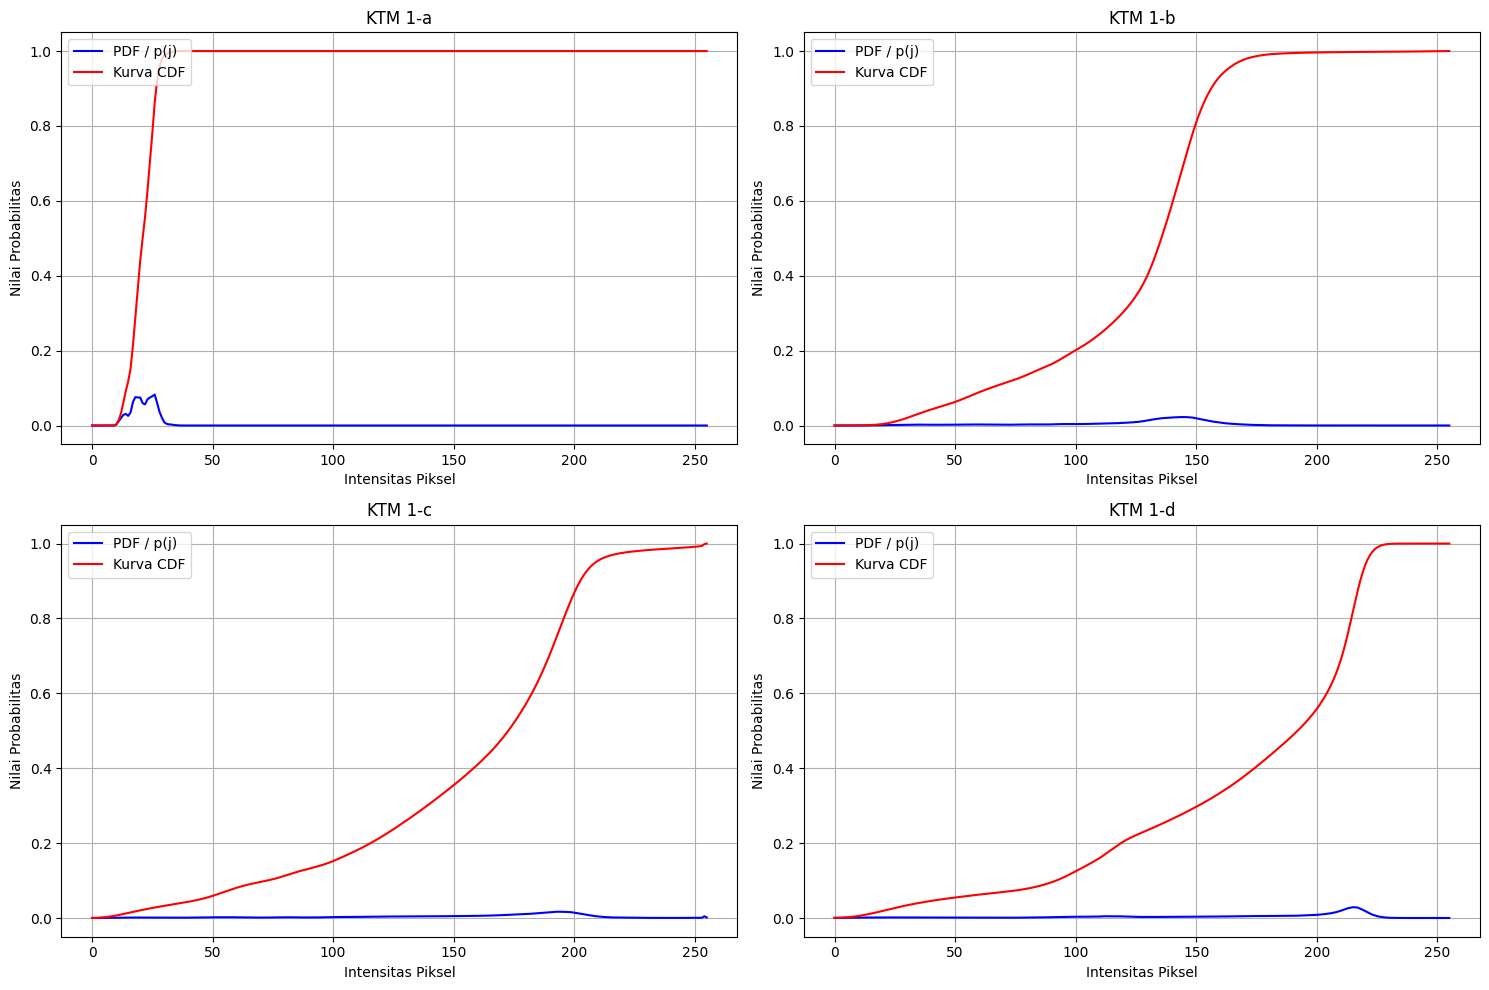

In [11]:
image_paths = [
    '/content/drive/MyDrive/PCVK/KTP1A.jpeg',
    '/content/drive/MyDrive/PCVK/KTP1B.jpeg',
    '/content/drive/MyDrive/PCVK/KTP1C.jpeg',
    '/content/drive/MyDrive/PCVK/KTP1D.jpeg'
]

fig, axs = plt.subplots(2, 2, figsize=(15, 10))
axs = axs.ravel()

for idx, path in enumerate(image_paths):
    img = cv.imread(path, cv.IMREAD_GRAYSCALE)
    if img is None:
        print(f"Gambar tidak ditemukan di: {path}")
        continue

    hist, bins = np.histogram(img.flatten(), 256, [0, 256])
    total_pixels = img.size
    p_j = hist / total_pixels

    cdf = p_j.cumsum()

    ax = axs[idx]
    ax.plot(p_j, color='blue', label='PDF / p(j)')
    ax.plot(cdf, color='red', label='Kurva CDF')
    ax.set_title(f'KTM 1-{chr(97+idx)}')
    ax.set_xlabel('Intensitas Piksel')
    ax.set_ylabel('Nilai Probabilitas')
    ax.legend(loc='upper left')
    ax.grid(True)

plt.tight_layout()
plt.show()

Bentuk Kurva CDF Citra Gelap: Kurva CDF-nya akan melonjak atau naik dengan cepat di bagian kiri (intensitas rendah/warna gelap). Ini karena sebagian besar piksel kumpul di area gelap.

Bentuk Kurva CDF Citra Terang: Kurva CDF-nya akan bergeser ke kanan dan landai di awal, lalu melonjak di bagian ujung kanan (intensitas tinggi).

Kaitan Pencahayaan: Jika kondisinya kurang cahaya (underexposed), kurva CDF akan menumpuk di sisi kiri. Sebaliknya, kalau kelebihan cahaya (overexposed/silau), kurva CDF-nya ketarik langsung ke sisi kanan.

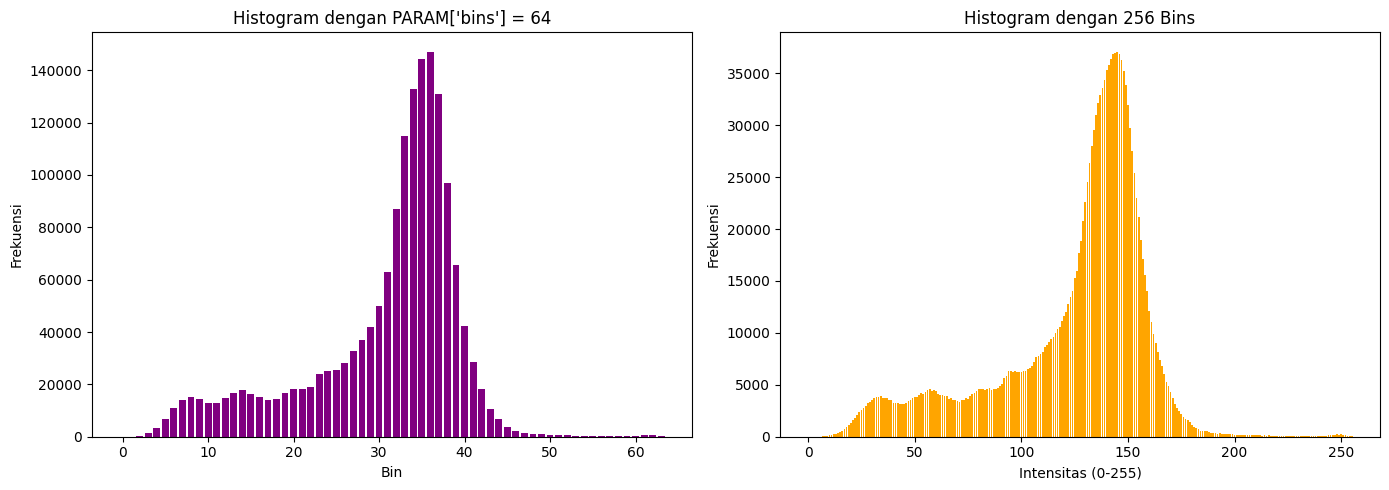

In [27]:
param_bins = 64

img_b = cv.imread('/content/drive/MyDrive/PCVK/KTP1B.jpeg', cv.IMREAD_GRAYSCALE)

hist_param, _ = np.histogram(img_b.flatten(), param_bins, [0, 256])
hist_256, _ = np.histogram(img_b.flatten(), 256, [0, 256])

fig, axs = plt.subplots(1, 2, figsize=(14, 5))

axs[0].bar(np.arange(param_bins), hist_param, color='purple')
axs[0].set_title(f"Histogram dengan PARAM['bins'] = {param_bins}")
axs[0].set_xlabel("Bin")
axs[0].set_ylabel("Frekuensi")

axs[1].bar(np.arange(256), hist_256, color='orange')
axs[1].set_title("Histogram dengan 256 Bins")
axs[1].set_xlabel("Intensitas (0-255)")
axs[1].set_ylabel("Frekuensi")

plt.tight_layout()
plt.show()

Ketika jumlah bin dikurangi (misalnya jadi 64 bin), detail distribusi intensitas warna jadi hilang (mereduksi informasi halus). Piksel-piksel yang punya intensitas berdekatan dipaksa masuk ke dalam satu kotak (bin) yang sama, sehingga kita tidak bisa melihat fluktuasi tajam atau detail spesifik dari nilai keabuan tiap piksel secara presisi seperti pada histogram 256 bin.

---



Gambar berhasil dibaca
Shape: (512, 512, 3)
Dtype: uint8
Height: 512
Width: 512
Depth: 3


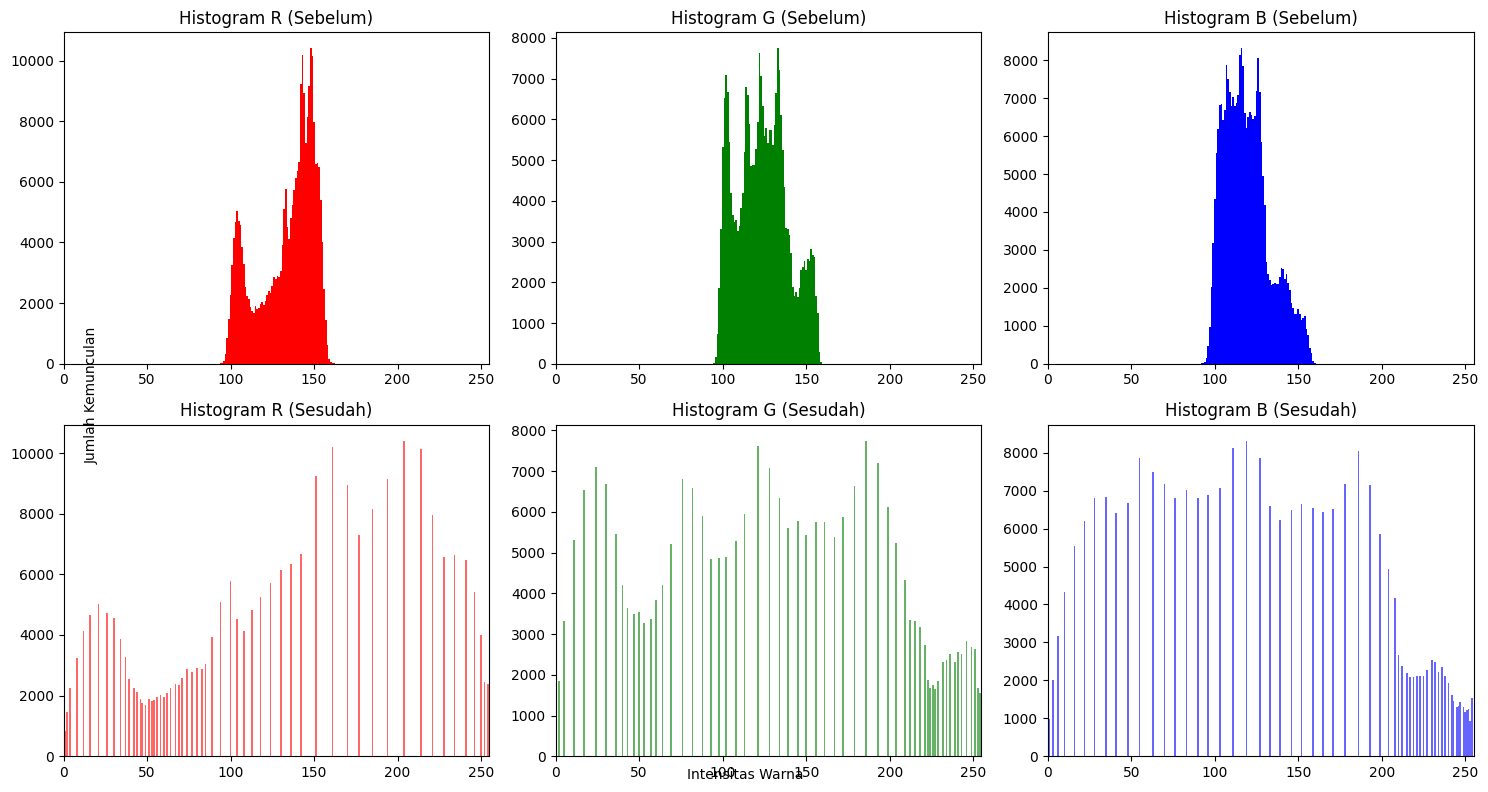

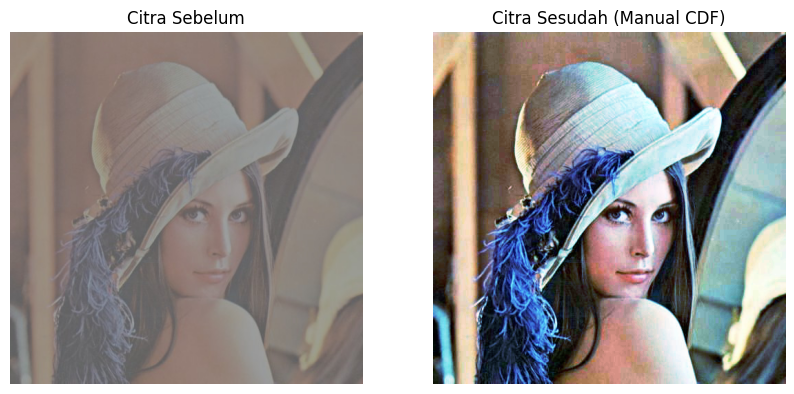

In [40]:


path_lena = '/content/drive/MyDrive/PCVK/lena_lc.jpg'
img_bgr = cv.imread(path_lena)

#Cek gambar berhasil dibaca
if img_bgr is None:
    print("Gambar tidak ditemukan!")
else:
    print("Gambar berhasil dibaca")
    print("Shape:", img_bgr.shape)
    print("Dtype:", img_bgr.dtype)


img_orig_rgb = cv.cvtColor(img_bgr, cv.COLOR_BGR2RGB)

height, width, depth = np.shape(img_orig_rgb)

print("Height:", height)
print("Width:", width)
print("Depth:", depth)


red = [0] * 256
green = [0] * 256
blue = [0] * 256

for y in range(height):
    for x in range(width):
        red[img_orig_rgb[y][x][0]] += 1
        green[img_orig_rgb[y][x][1]] += 1
        blue[img_orig_rgb[y][x][2]] += 1



def manual_histogram_equalization(channel):

    #Hitung histogram
    hist = [0] * 256

    height, width = channel.shape

    for y in range(height):
        for x in range(width):
            hist[channel[y][x]] += 1

    #Hitung CDF
    cdf = [0] * 256
    cdf[0] = hist[0]

    for i in range(1, 256):
        cdf[i] = cdf[i - 1] + hist[i]

    #Cari CDF minimum yang bukan 0
    cdf_min = 0

    for value in cdf:
        if value > 0:
            cdf_min = value
            break

    #Jumlah piksel
    total_pixels = height * width

    #Buat tabel mapping
    mapping = [0] * 256

    for i in range(256):
        if cdf[i] == 0:
            mapping[i] = 0
        else:
            mapping[i] = int(
                ((cdf[i] - cdf_min) * 255) /
                (total_pixels - cdf_min)
            )

    #Terapkan mapping ke setiap piksel
    img_eq = np.zeros_like(channel)

    for y in range(height):
        for x in range(width):
            img_eq[y][x] = mapping[channel[y][x]]

    return img_eq


#Pisahkan channel BGR
b_orig, g_orig, r_orig = cv.split(img_bgr)

#Equalization masing-masing channel
r_eq = manual_histogram_equalization(r_orig)
g_eq = manual_histogram_equalization(g_orig)
b_eq = manual_histogram_equalization(b_orig)


#gabungkan channel
img_eq_bgr = cv.merge((b_eq, g_eq, r_eq))

# BGR -> RGB supaya bisa ditampilkan matplotlib
img_eq_rgb = cv.cvtColor(img_eq_bgr, cv.COLOR_BGR2RGB)



red_after = [0] * 256
green_after = [0] * 256
blue_after = [0] * 256

for y in range(height):
    for x in range(width):
        red_after[img_eq_rgb[y][x][0]] += 1
        green_after[img_eq_rgb[y][x][1]] += 1
        blue_after[img_eq_rgb[y][x][2]] += 1




names = np.arange(256)

fig, axs = plt.subplots(2, 3, figsize=(15, 8))


#batas atas sebelum
axs[0, 0].bar(
    names,
    red,
    color='red',
    width=1
)
axs[0, 0].set_title("Histogram R (Sebelum)")

axs[0, 1].bar(
    names,
    green,
    color='green',
    width=1
)
axs[0, 1].set_title("Histogram G (Sebelum)")

axs[0, 2].bar(
    names,
    blue,
    color='blue',
    width=1
)
axs[0, 2].set_title("Histogram B (Sebelum)")

#batas atas sesudah
axs[1, 0].bar(
    names,
    red_after,
    color='red',
    width=1,
    alpha=0.6
)
axs[1, 0].set_title("Histogram R (Sesudah)")

axs[1, 1].bar(
    names,
    green_after,
    color='green',
    width=1,
    alpha=0.6
)
axs[1, 1].set_title("Histogram G (Sesudah)")

axs[1, 2].bar(
    names,
    blue_after,
    color='blue',
    width=1,
    alpha=0.6
)
axs[1, 2].set_title("Histogram B (Sesudah)")


#Batas sumbu X
for ax_row in axs:
    for ax in ax_row:
        ax.set_xlim([0, 255])


fig.text(
    0.5,
    0.02,
    'Intensitas Warna',
    ha='center'
)

fig.text(
    0.06,
    0.5,
    'Jumlah Kemunculan',
    va='center',
    rotation='vertical'
)

plt.tight_layout()
plt.show()




fig2, ax2 = plt.subplots(
    1,
    2,
    figsize=(10, 5)
)

ax2[0].imshow(img_orig_rgb)
ax2[0].set_title("Citra Sebelum")
ax2[0].axis('off')

ax2[1].imshow(img_eq_rgb)
ax2[1].set_title("Citra Sesudah (Manual CDF)")
ax2[1].axis('off')

plt.show()




File: /content/drive/MyDrive/PCVK/lena_lc.jpg
Selisih maksimum channel B: 1
Selisih maksimum channel G: 1
Selisih maksimum channel R: 1
Selisih maksimum keseluruhan: 1


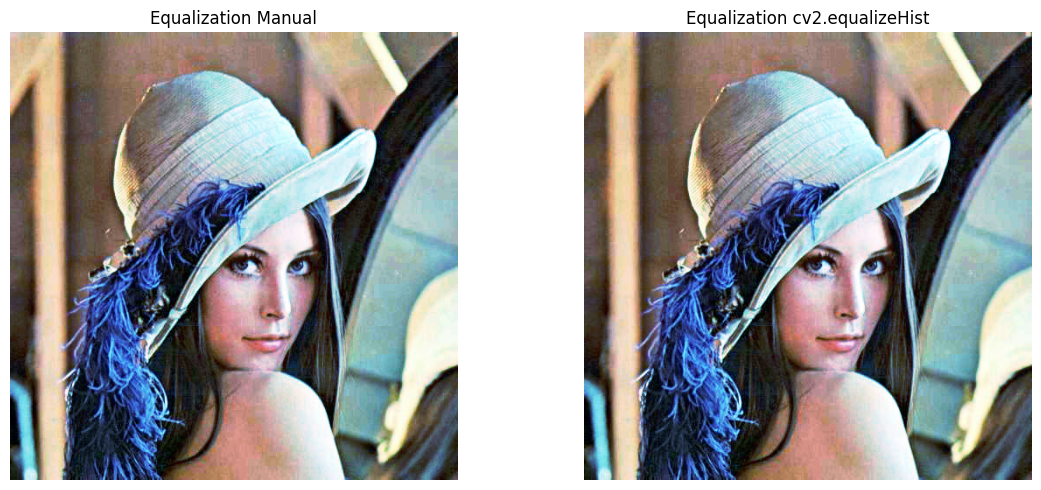

File: /content/drive/MyDrive/PCVK/KTP1D.jpeg
Selisih maksimum channel B: 1
Selisih maksimum channel G: 1
Selisih maksimum channel R: 1
Selisih maksimum keseluruhan: 1


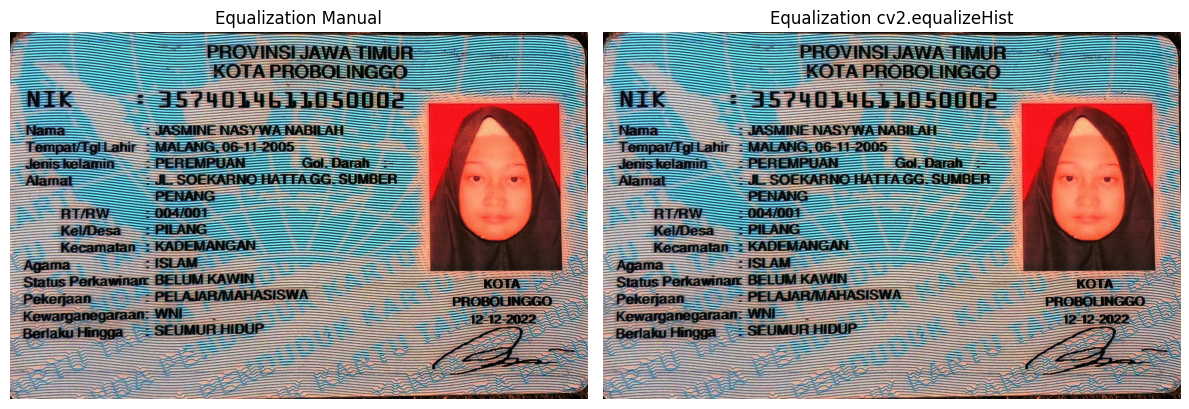

In [30]:
# EQUALIZATION MENGGUNAKAN cv2.equalizeHist()
# DAN PERBANDINGAN DENGAN HASIL MANUAL

# FUNGSI HISTOGRAM EQUALIZATION MANUAL


def manual_histogram_equalization(channel):

    #Hitung histogram secara manual
    hist = [0] * 256

    height, width = channel.shape

    for y in range(height):
        for x in range(width):
            hist[channel[y][x]] += 1


    cdf = [0] * 256
    cdf[0] = hist[0]

    for i in range(1, 256):
        cdf[i] = cdf[i - 1] + hist[i]


    cdf_min = 0

    for value in cdf:
        if value > 0:
            cdf_min = value
            break


    total_pixels = height * width


    mapping = [0] * 256

    for i in range(256):
        if cdf[i] == 0:
            mapping[i] = 0
        else:
            mapping[i] = int(
                ((cdf[i] - cdf_min) * 255) /
                (total_pixels - cdf_min)
            )


    img_eq = np.zeros_like(channel)

    for y in range(height):
        for x in range(width):
            img_eq[y][x] = mapping[channel[y][x]]

    return img_eq



#FUNGSI PERBANDINGAN


def compare_manual_vs_cv2(path):

    print("=" * 60)
    print("File:", path)


    image = cv.imread(path)

    if image is None:
        print("Gambar tidak ditemukan!")
        return

    #Pisahkan channel


    b, g, r = cv.split(image)


    #Equalization manual


    b_manual = manual_histogram_equalization(b)
    g_manual = manual_histogram_equalization(g)
    r_manual = manual_histogram_equalization(r)

    manual_result = cv.merge(
        (b_manual, g_manual, r_manual)
    )


    #Equalization menggunakan OpenCV


    b_cv2 = cv.equalizeHist(b)
    g_cv2 = cv.equalizeHist(g)
    r_cv2 = cv.equalizeHist(r)

    cv2_result = cv.merge(
        (b_cv2, g_cv2, r_cv2)
    )


    #Hitung selisih


    diff_b = cv.absdiff(b_manual, b_cv2)
    diff_g = cv.absdiff(g_manual, g_cv2)
    diff_r = cv.absdiff(r_manual, r_cv2)

    max_diff_b = np.max(diff_b)
    max_diff_g = np.max(diff_g)
    max_diff_r = np.max(diff_r)

    #Selisih maksimum seluruh channel
    max_difference = max(
        max_diff_b,
        max_diff_g,
        max_diff_r
    )

    print("Selisih maksimum channel B:", max_diff_b)
    print("Selisih maksimum channel G:", max_diff_g)
    print("Selisih maksimum channel R:", max_diff_r)
    print("Selisih maksimum keseluruhan:", max_difference)


    #Tampilkan hasil


    manual_rgb = cv.cvtColor(
        manual_result,
        cv.COLOR_BGR2RGB
    )

    cv2_rgb = cv.cvtColor(
        cv2_result,
        cv.COLOR_BGR2RGB
    )

    fig, ax = plt.subplots(
        1, 2,
        figsize=(12, 5)
    )

    ax[0].imshow(manual_rgb)
    ax[0].set_title("Equalization Manual")
    ax[0].axis('off')

    ax[1].imshow(cv2_rgb)
    ax[1].set_title("Equalization cv2.equalizeHist")
    ax[1].axis('off')

    plt.tight_layout()
    plt.show()

    return manual_result, cv2_result



#TEST lena_lc.jpg


lena_manual, lena_cv2 = compare_manual_vs_cv2(
    '/content/drive/MyDrive/PCVK/lena_lc.jpg'
)



#TEST KTP1d.jpg


ktm_manual, ktm_cv2 = compare_manual_vs_cv2(
    '/content/drive/MyDrive/PCVK/KTP1D.jpeg'
)

Gambar berhasil dibaca
Shape: (1000, 1575, 3)


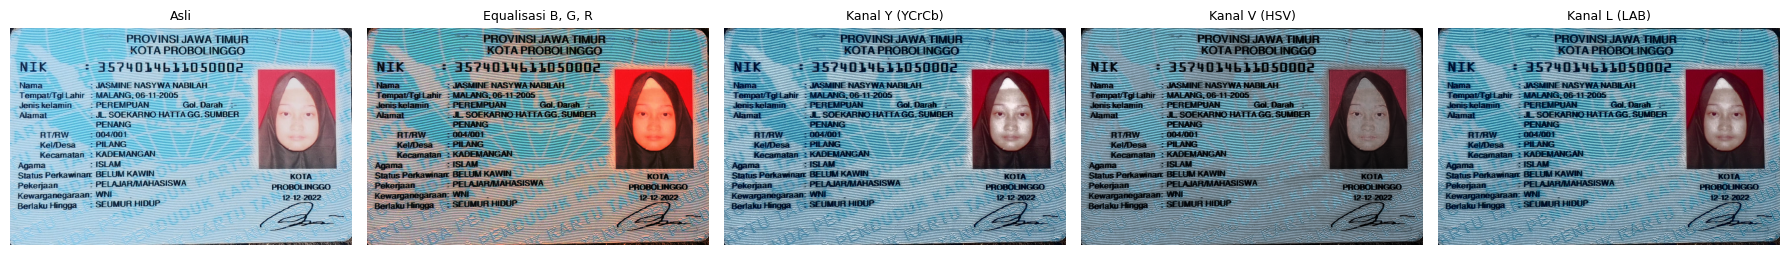

In [32]:

# NO. 4
# EQUALISASI CHANNEL TERANG PADA
# BEBERAPA RUANG WARNA




berkas = '/content/drive/MyDrive/PCVK/KTP1D.jpeg'

bgr = cv.imread(berkas)

if bgr is None:
    print("Gambar tidak ditemukan!")
else:
    print("Gambar berhasil dibaca")
    print("Shape:", bgr.shape)



#EQUALISASI CHANNEL B, G, R


kanal = list(cv.split(bgr))

for i in range(3):
    kanal[i] = cv.equalizeHist(kanal[i])

he_rgb = cv.merge(kanal)



#EQUALISASI CHANNEL Y PADA YCrCb


ycrcb = cv.cvtColor(
    bgr,
    cv.COLOR_BGR2YCrCb
)

y, cr, cb = cv.split(ycrcb)

he_y = cv.cvtColor(
    cv.merge([
        cv.equalizeHist(y),
        cr,
        cb
    ]),
    cv.COLOR_YCrCb2BGR
)


#VARIAN HSV

hsv = cv.cvtColor(
    bgr,
    cv.COLOR_BGR2HSV
)

h, sat, v = cv.split(hsv)

he_v = cv.cvtColor(
    cv.merge([
        h,
        sat,
        cv.equalizeHist(v)
    ]),
    cv.COLOR_HSV2BGR
)

#EQUALISASI CHANNEL L


lab = cv.cvtColor(
    bgr,
    cv.COLOR_BGR2LAB
)

l, a, b = cv.split(lab)

he_l = cv.cvtColor(
    cv.merge([
        cv.equalizeHist(l),
        a,
        b
    ]),
    cv.COLOR_LAB2BGR
)


judul = [
    'Asli',
    'Equalisasi B, G, R',
    'Kanal Y (YCrCb)',
    'Kanal V (HSV)',
    'Kanal L (LAB)'
]

citra = [
    bgr,
    he_rgb,
    he_y,
    he_v,
    he_l
]



plt.figure(figsize=(18, 4))

for i, (c, t) in enumerate(zip(citra, judul), 1):

    plt.subplot(1, 5, i)

    plt.imshow(
        cv.cvtColor(c, cv.COLOR_BGR2RGB)
    )

    plt.title(t, fontsize=9)
    plt.axis('off')

plt.tight_layout()
plt.show()

In [34]:

def geser_hue(asli, hasil):

    h1 = cv.cvtColor(
        asli,
        cv.COLOR_BGR2HSV
    )[:, :, 0].astype(np.int16)

    h2 = cv.cvtColor(
        hasil,
        cv.COLOR_BGR2HSV
    )[:, :, 0].astype(np.int16)

    d = np.abs(h2 - h1)

    # Hue melingkar 0-179
    d = np.minimum(d, 180 - d)

    return d.mean()
hasil_tabel = []

for t, c in zip(judul, citra):

    hue_shift = geser_hue(bgr, c) * 2

    brightness = cv.cvtColor(
        c,
        cv.COLOR_BGR2GRAY
    ).mean()

    hasil_tabel.append([
        t,
        hue_shift,
        brightness
    ])


print("\nTABEL HASIL")
print("-" * 70)
print(
    f"{'Cara':<25}"
    f"{'Rata-rata Hue (derajat)':>25}"
    f"{'Rerata Kecerahan':>20}"
)
print("-" * 70)

for row in hasil_tabel:

    print(
        f"{row[0]:<25}"
        f"{row[1]:>25.2f}"
        f"{row[2]:>20.2f}"
    )


TABEL HASIL
----------------------------------------------------------------------
Cara                       Rata-rata Hue (derajat)    Rerata Kecerahan
----------------------------------------------------------------------
Asli                                          0.00              169.82
Equalisasi B, G, R                           64.09              127.78
Kanal Y (YCrCb)                               2.34              129.12
Kanal V (HSV)                                 1.33              109.78
Kanal L (LAB)                                 3.10              119.40


Gambar berhasil dibaca
Shape : (935, 1473)
Dtype : uint8
Min   : 9
Max   : 45


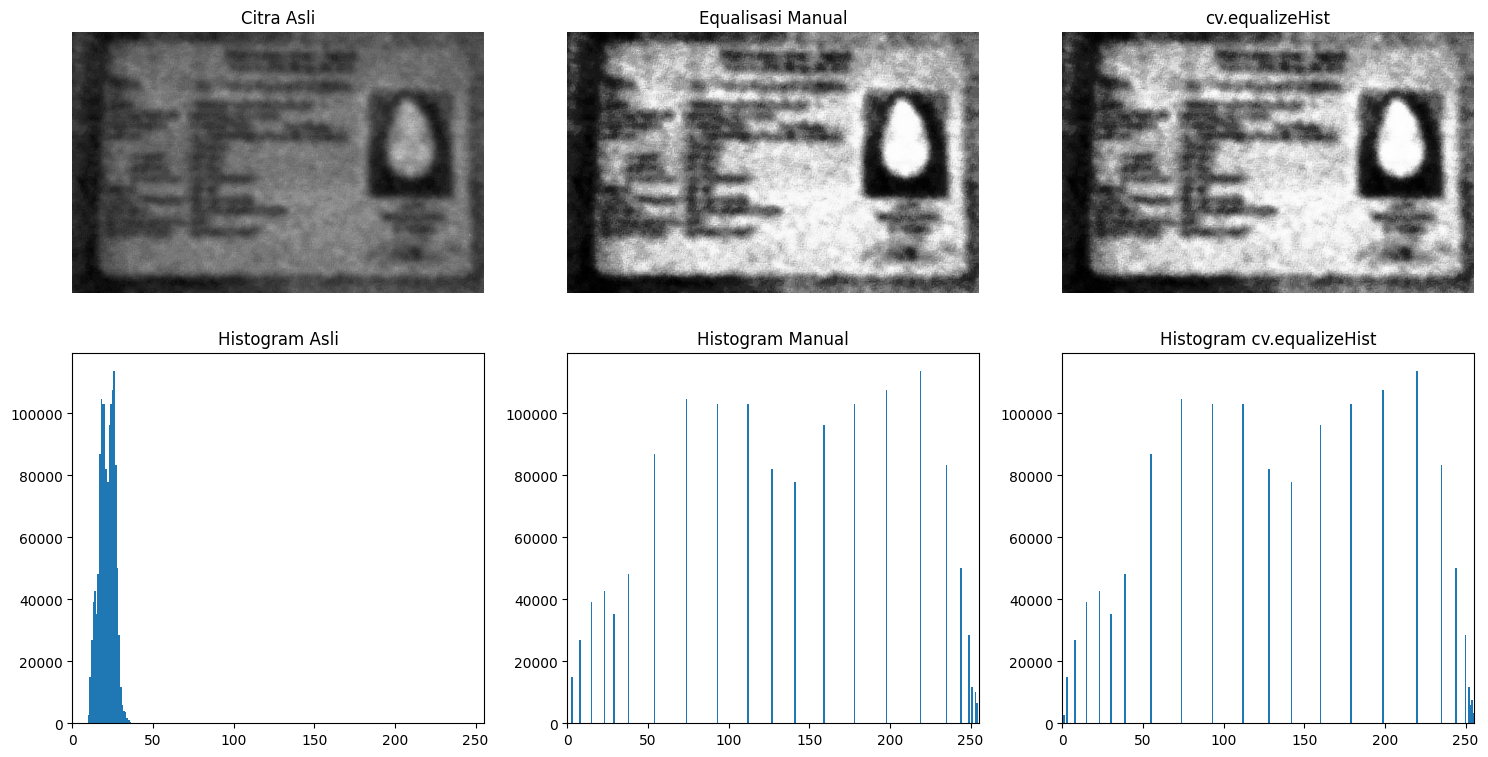

HASIL PSNR
PSNR Manual     : 5.66 dB
PSNR cv.equalizeHist : 5.63 dB


In [36]:

# PERTANYAAN PRAKTIKUM E2


#NO1 EVALUASI GLOBAL PADA CITRA KTM


import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt


path_ktm = '/content/drive/MyDrive/PCVK/KTP1A.jpeg'

img = cv.imread(
    path_ktm,
    cv.IMREAD_GRAYSCALE
)

if img is None:
    print("Gambar tidak ditemukan!")
else:
    print("Gambar berhasil dibaca")
    print("Shape :", img.shape)
    print("Dtype :", img.dtype)
    print("Min   :", img.min())
    print("Max   :", img.max())


def manual_histogram_equalization(channel):

    hist = [0] * 256

    height, width = channel.shape

    for y in range(height):
        for x in range(width):
            hist[channel[y][x]] += 1

    cdf = [0] * 256

    cdf[0] = hist[0]

    for i in range(1, 256):
        cdf[i] = cdf[i - 1] + hist[i]


    cdf_min = 0

    for value in cdf:
        if value > 0:
            cdf_min = value
            break


    total_pixels = height * width

    mapping = [0] * 256

    for i in range(256):

        if cdf[i] == 0:

            mapping[i] = 0

        else:

            mapping[i] = int(
                ((cdf[i] - cdf_min) * 255) /
                (total_pixels - cdf_min)
            )

    img_eq = np.zeros_like(channel)

    for y in range(height):
        for x in range(width):

            img_eq[y][x] = mapping[
                channel[y][x]
            ]

    return img_eq



img_manual = manual_histogram_equalization(img)

img_cv2 = cv.equalizeHist(img)



hist_original = [0] * 256
hist_manual = [0] * 256
hist_cv2 = [0] * 256


height, width = img.shape

for y in range(height):
    for x in range(width):

        hist_original[
            img[y][x]
        ] += 1

        hist_manual[
            img_manual[y][x]
        ] += 1

        hist_cv2[
            img_cv2[y][x]
        ] += 1



fig, axs = plt.subplots(
    2,
    3,
    figsize=(15, 8)
)




axs[0, 0].imshow(
    img,
    cmap='gray'
)

axs[0, 0].set_title(
    "Citra Asli"
)

axs[0, 0].axis('off')


axs[0, 1].imshow(
    img_manual,
    cmap='gray'
)

axs[0, 1].set_title(
    "Equalisasi Manual"
)

axs[0, 1].axis('off')


axs[0, 2].imshow(
    img_cv2,
    cmap='gray'
)

axs[0, 2].set_title(
    "cv.equalizeHist"
)

axs[0, 2].axis('off')


#histogram

intensitas = np.arange(256)


axs[1, 0].bar(
    intensitas,
    hist_original,
    width=1
)

axs[1, 0].set_title(
    "Histogram Asli"
)

axs[1, 0].set_xlim(
    [0, 255]
)


axs[1, 1].bar(
    intensitas,
    hist_manual,
    width=1
)

axs[1, 1].set_title(
    "Histogram Manual"
)

axs[1, 1].set_xlim(
    [0, 255]
)


axs[1, 2].bar(
    intensitas,
    hist_cv2,
    width=1
)

axs[1, 2].set_title(
    "Histogram cv.equalizeHist"
)

axs[1, 2].set_xlim(
    [0, 255]
)


plt.tight_layout()
plt.show()


#psnr

def hitung_psnr(asli, hasil):

    # Mean Squared Error
    mse = np.mean(
        (asli.astype(np.float64) -
         hasil.astype(np.float64)) ** 2
    )

    # Jika identik
    if mse == 0:
        return float('inf')

    # PSNR
    psnr = 10 * np.log10(
        (255 ** 2) / mse
    )

    return psnr




psnr_manual = hitung_psnr(
    img,
    img_manual
)

psnr_cv2 = hitung_psnr(
    img,
    img_cv2
)


print("==========================================")
print("HASIL PSNR")
print("==========================================")

print(
    f"PSNR Manual     : {psnr_manual:.2f} dB"
)

print(
    f"PSNR cv.equalizeHist : {psnr_cv2:.2f} dB"
)

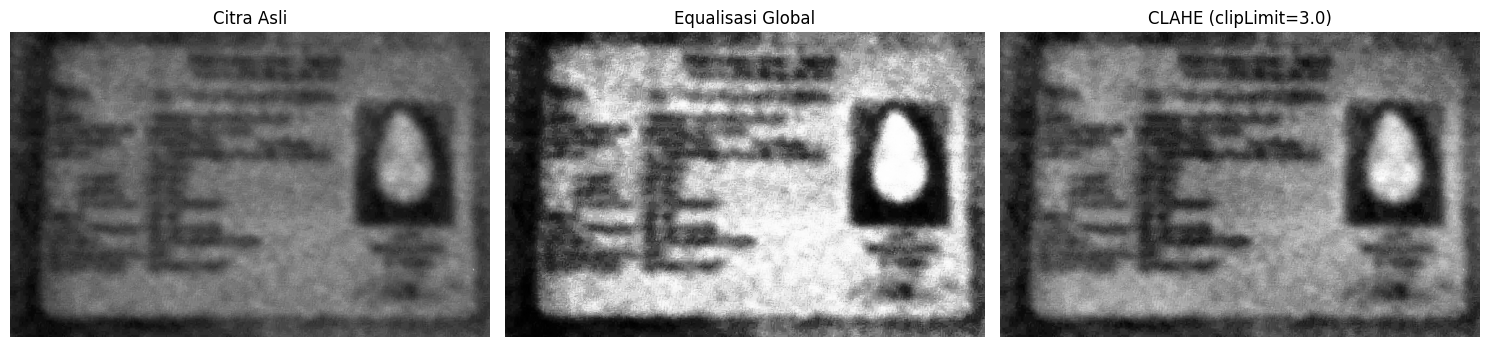

In [38]:

# PERTANYAAN PRAKTIKUM E2
# NO2 CLAHE




# 1. PARAMETER CLAHE


clip_utama = 3.0
tile = 5


# 2. BUAT CLAHE


clahe = cv.createCLAHE(
    clipLimit=clip_utama,
    tileGridSize=(tile, tile)
)


# 3. TERAPKAN CLAHE


img_clahe = clahe.apply(img)


# 4. TAMPILKAN PERBANDINGAN


fig, axs = plt.subplots(
    1,
    3,
    figsize=(15, 5)
)


axs[0].imshow(
    img,
    cmap='gray'
)

axs[0].set_title(
    "Citra Asli"
)

axs[0].axis('off')


axs[1].imshow(
    img_cv2,
    cmap='gray'
)

axs[1].set_title(
    "Equalisasi Global"
)

axs[1].axis('off')


axs[2].imshow(
    img_clahe,
    cmap='gray'
)

axs[2].set_title(
    f"CLAHE (clipLimit={clip_utama})"
)

axs[2].axis('off')


plt.tight_layout()
plt.show()

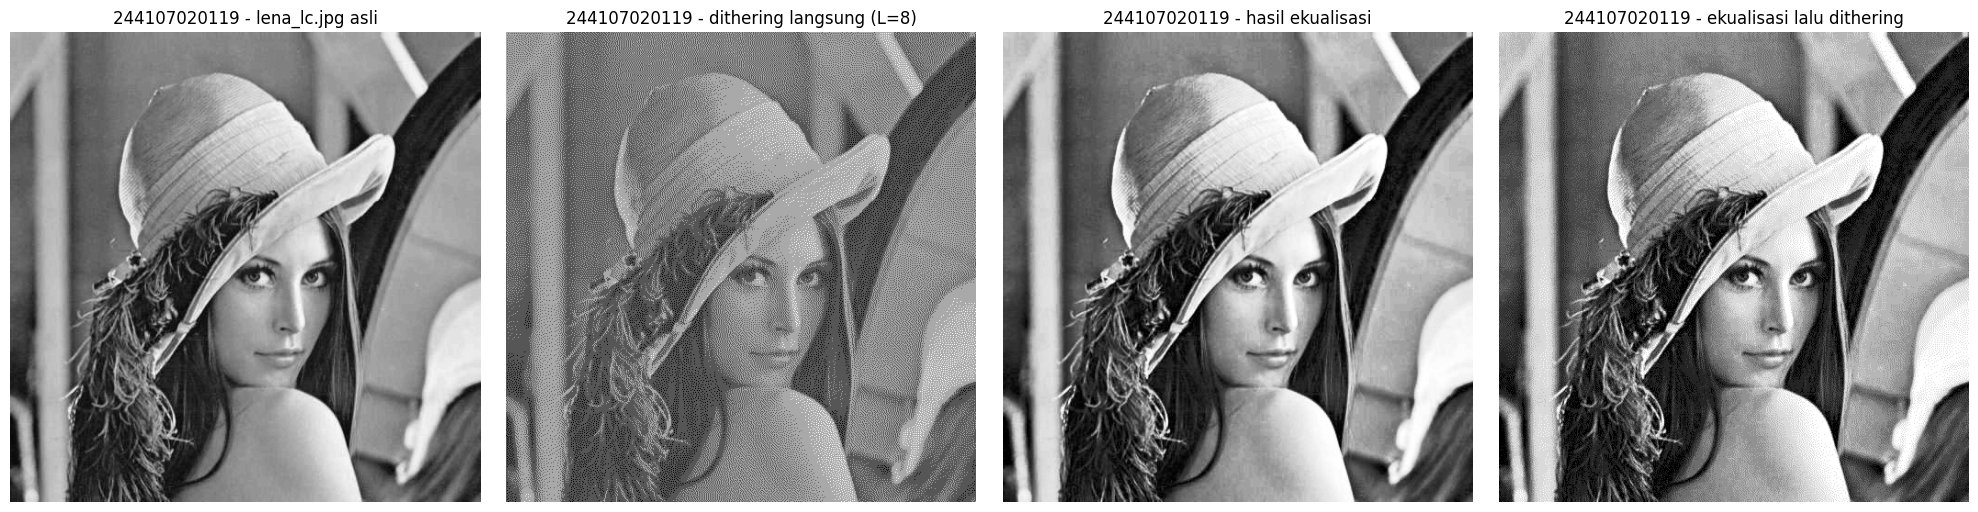

In [39]:
# FUNGSI FLOYD-STEINBERG DITHERING
def floyd_steinberg_dither(gray_img, L):
    img_float = gray_img.astype(np.float32)
    H, W = img_float.shape
    step = 255.0 / (L - 1) if L > 1 else 255.0


    for y in range(H):
        for x in range(W):
            lama = img_float[y, x]

            baru = round(lama / step) * step
            img_float[y, x] = baru
            error = lama - baru

            # Difusi error ke tetangga-tetangganya
            # 1. Kanan: (y, x + 1) += error * 7/16
            if x + 1 < W:
                img_float[y, x + 1] += error * 7 / 16.0

            # 2. Kiri-Bawah: (y + 1, x - 1) += error * 3/16
            if x > 0 and y + 1 < H:
                img_float[y + 1, x - 1] += error * 3 / 16.0

            # 3. Bawah: (y + 1, x) += error * 5/16
            if y + 1 < H:
                img_float[y + 1, x] += error * 5 / 16.0

            # 4. Kanan-Bawah: (y + 1, x + 1) += error * 1/16
            if x + 1 < W and y + 1 < H:
                img_float[y + 1, x + 1] += error * 1 / 16.0

    # Batasi nilai citra ke rentang 0 - 255 lalu ubah ke uint8
    img_dithered = np.clip(img_float, 0, 255).astype(np.uint8)
    return img_dithered


path_lena = '/content/drive/MyDrive/PCVK/lena_lc.jpg'
img_bgr = cv.imread(path_lena)
img_gray = cv.cvtColor(img_bgr, cv.COLOR_BGR2GRAY)


L_level = PARAM['L']

# A. Dithering langsung pada citra asli (tanpa ekualisasi)
img_dither_langsung = floyd_steinberg_dither(img_gray, L=L_level)

# B. Ekualisasi histogram terlebih dahulu, baru dithering
img_eq = cv.equalizeHist(img_gray)
img_dither_eq = floyd_steinberg_dither(img_eq, L=L_level)


fig, axs = plt.subplots(1, 4, figsize=(20, 5))

axs[0].imshow(img_gray, cmap='gray')
axs[0].set_title(f"{NIM} - lena_lc.jpg asli")
axs[0].axis('off')

axs[1].imshow(img_dither_langsung, cmap='gray')
axs[1].set_title(f"{NIM} - dithering langsung (L={L_level})")
axs[1].axis('off')

axs[2].imshow(img_eq, cmap='gray')
axs[2].set_title(f"{NIM} - hasil ekualisasi")
axs[2].axis('off')

axs[3].imshow(img_dither_eq, cmap='gray')
axs[3].set_title(f"{NIM} - ekualisasi lalu dithering")
axs[3].axis('off')

plt.tight_layout()
plt.show()